# 04 - Result analysis - the "so what" notebook

Rules of this notebook: **load artifacts, never retrain**; every metric gets a
business translation; and it ends with the single number the suite exists to
produce - **Revenue at Risk**, per customer, ranked.

In [1]:
import sys
from pathlib import Path

# Make src/ importable whether Jupyter starts in the project root or in Code/
for candidate in (Path.cwd(), Path.cwd() / "Code", Path.cwd().parent):
    if (candidate / "phase_1").exists():
        sys.path.insert(0, str(candidate))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)

from phase_1.loader import load_processed, load_telco
from phase_1 import eda, evaluation, models
eda.set_style()

test = load_processed("telco_test")
X_test, y_test = test.drop(columns=["Churn"]), test["Churn"]
zoo_bundle = models.load_model("churn_zoo")
champ_bundle = models.load_model("churn_pipeline")
all_models = {**zoo_bundle["models"], "tuned_hgb": champ_bundle["pipeline"]}
proba = champ_bundle["pipeline"].predict_proba(X_test)[:, 1]

## 1. Lens A - model comparison

PR-AUC is the honest headline under 27% prevalence. The @0.5 columns exist only to
show why the default threshold is wrong - recall at 0.5 leaves churners on the table.

In [2]:
evaluation.score_table(all_models, X_test, y_test)

,model,roc_auc,pr_auc,recall@0.5,precision@0.5,f1@0.5
0,tuned_hgb,0.8448,0.6552,0.8048,0.5253,0.6357
1,random_forest,0.8429,0.6483,0.7380,0.5531,0.6323
2,logistic_regression,0.8426,0.6377,0.7914,0.5043,0.6160
3,hist_gradient_boosting,0.8346,0.6429,0.7326,0.5341,0.6178


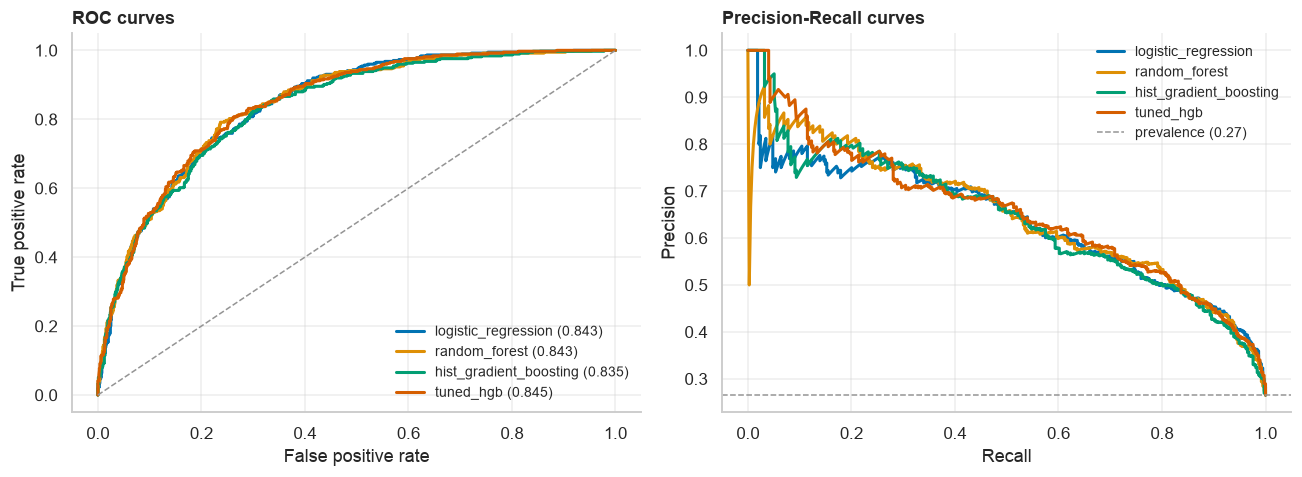

In [3]:
evaluation.plot_roc_pr(all_models, X_test, y_test)
plt.show()

### 1.1 Are the probabilities *numbers* or just rankings?

Revenue-at-Risk multiplies these probabilities by dollars, so they must be calibrated:
predicted 60% should churn ~60% of the time.

In [4]:
evaluation.calibration_table(y_test, proba)

,bin,n,mean_predicted,observed_rate
0,"(0.0, 0.1]",318,0.069,0.013
1,"(0.1, 0.2]",134,0.145,0.060
2,"(0.2, 0.3]",135,0.253,0.119
3,"(0.3, 0.4]",142,0.349,0.176
4,"(0.4, 0.5]",107,0.445,0.187
5,"(0.5, 0.6]",107,0.556,0.336
6,"(0.6, 0.7]",133,0.648,0.421
7,"(0.7, 0.8]",169,0.751,0.550
8,"(0.8, 0.9]",159,0.848,0.698
9,"(0.9, 1.0]",5,0.904,1.000


### 1.2 Cost-based threshold - the decision, not just the score

Missing a churner costs a customer lifetime (~$500 here); a retention offer costs ~$50.
The cost-minimizing threshold lands well below 0.5 - and the sensitivity check shows
the *decision* is stable even when the cost guesses move.

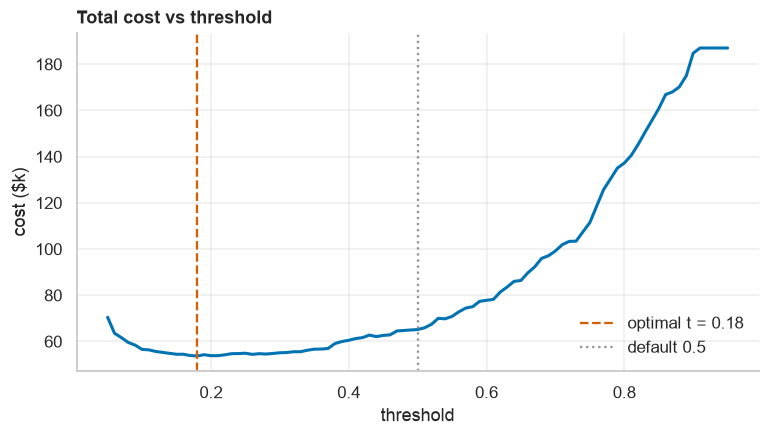

missed=$ 500, offer=$  50 -> optimal threshold 0.18
missed=$ 300, offer=$  50 -> optimal threshold 0.37
missed=$ 500, offer=$  25 -> optimal threshold 0.12
missed=$ 800, offer=$ 100 -> optimal threshold 0.28


In [5]:
best_t, curve = evaluation.cost_optimal_threshold(y_test, proba, 500, 50)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve["threshold"], curve["total_cost"] / 1000, color=eda.PALETTE[0], linewidth=2)
ax.axvline(best_t, color=eda.PALETTE[3], linestyle="--",
           label=f"optimal t = {best_t:.2f}")
ax.axvline(0.5, color=eda.CONTEXT_COLOR, linestyle=":", label="default 0.5")
ax.set(title="Total cost vs threshold", xlabel="threshold", ylabel="cost ($k)")
ax.legend(frameon=False)
plt.show()

for costs in [(500, 50), (300, 50), (500, 25), (800, 100)]:
    t, _ = evaluation.cost_optimal_threshold(y_test, proba, *costs)
    print(f"missed=${costs[0]:>4}, offer=${costs[1]:>4} -> optimal threshold {t:.2f}")

### 1.3 Lift & gains - the recruiter number

"If the retention team can only call 10% of customers, the model finds ~3x more
churners in that call list than random selection." That sentence is the project.

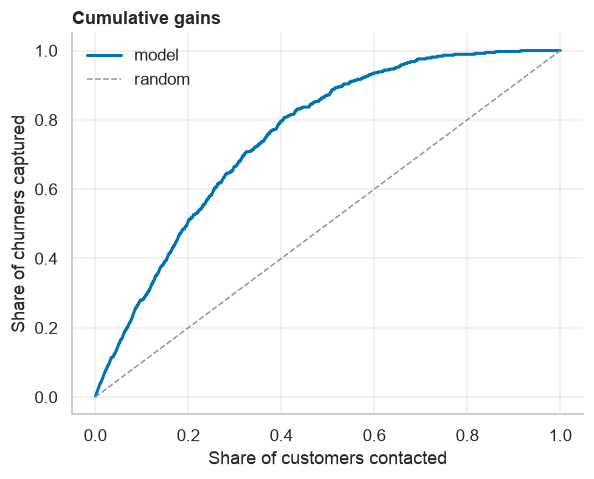

,decile,n,churners,churn_rate,min_proba,lift,cum_capture
0,1,141,105,0.745,0.814,2.805,0.281
1,2,141,85,0.603,0.736,2.271,0.508
2,3,141,59,0.418,0.629,1.576,0.666
3,4,141,49,0.348,0.516,1.309,0.797
4,5,141,28,0.199,0.379,0.748,0.872
5,6,140,24,0.171,0.285,0.646,0.936
6,7,141,15,0.106,0.170,0.401,0.976
7,8,141,5,0.035,0.091,0.134,0.989
8,9,141,3,0.021,0.060,0.080,0.997
9,10,141,1,0.007,0.054,0.027,1.000


In [6]:
lift = evaluation.lift_table(y_test, proba)
evaluation.gains_chart(y_test, proba)
plt.show()
lift

### 1.4 What drives the predictions

Permutation importance on the held-out set (model-agnostic, interaction-aware).
Translate, don't recite: *contract commitment, lifecycle stage, and support coverage
drive churn - price only amplifies them.*

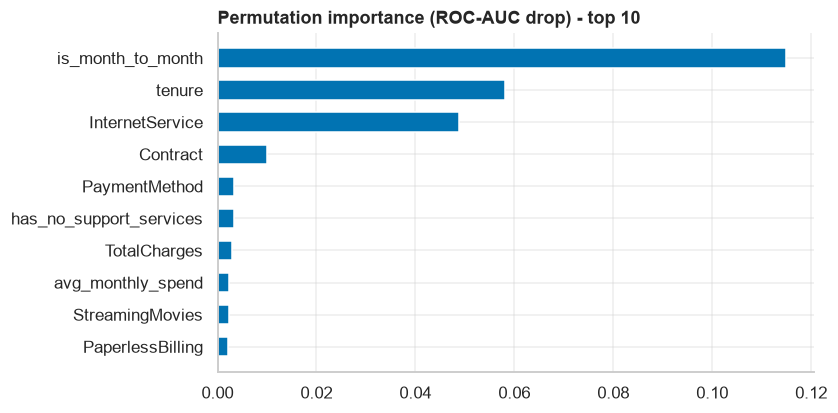

In [7]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(champ_bundle["pipeline"], X_test, y_test,
                             scoring="roc_auc", n_repeats=5, random_state=42)
top = (pd.Series(imp.importances_mean, index=X_test.columns)
       .sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index[::-1], top.values[::-1], color=eda.PALETTE[0], height=0.6)
ax.set_title("Permutation importance (ROC-AUC drop) - top 10")
plt.show()

### 1.5 Error analysis - who do we get wrong?

False negatives (missed churners) are the expensive mistake. Profile them: they skew
long-tenure, on contracts - churners who *look* safe. Honest limitation for the
model card: quiet quitters need behavioral/usage data we don't have.

In [8]:
pred = (proba >= best_t).astype(int)
fn = X_test[(y_test == 1) & (pred == 0)]
tp = X_test[(y_test == 1) & (pred == 1)]
comparison = pd.DataFrame({
    "missed churners (FN)": fn[["tenure", "MonthlyCharges", "services_count"]].mean(),
    "caught churners (TP)": tp[["tenure", "MonthlyCharges", "services_count"]].mean(),
}).round(1)
print(f"missed {len(fn)} of {int(y_test.sum())} churners at t={best_t}")
print(f"share of FN on month-to-month: {(fn['Contract']=='Month-to-month').mean():.0%} "
      f"vs TP: {(tp['Contract']=='Month-to-month').mean():.0%}")
comparison

missed 10 of 374 churners at t=0.18
share of FN on month-to-month: 0% vs TP: 90%


,missed churners (FN),caught churners (TP)
tenure,36.7,15.9
MonthlyCharges,57.8,73.2
services_count,3.7,3.0


## 2. Lens B - when they leave

C-indices from notebook 03 (~0.85+, strong ranking). The product of this lens:
**expected remaining tenure** per customer - plotted here by contract to show it
behaves, exported as the CLV bridge.

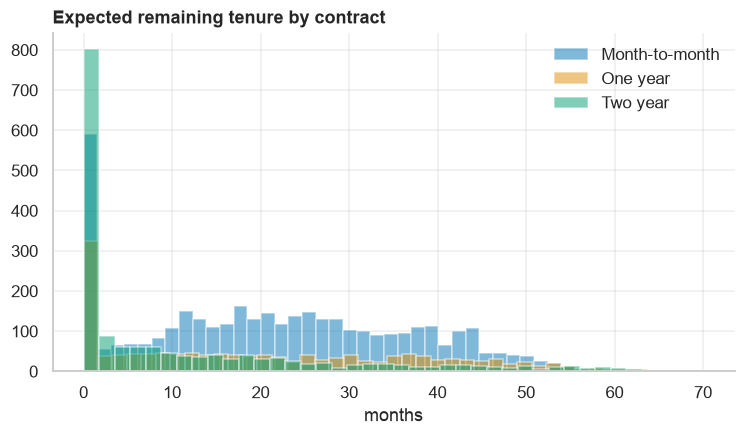

0.8579957996878651


In [9]:
from phase_1.preprocessing import encode_for_survival

telco = load_telco()
cox_bundle = models.load_model("cox_bundle")
sdf = encode_for_survival(telco)
remaining = models.expected_remaining_tenure(cox_bundle["model"], sdf)
telco_r = telco.assign(remaining=remaining)
fig, ax = plt.subplots(figsize=(8, 4))
for contract, color in zip(telco_r["Contract"].unique(), eda.PALETTE):
    sub = telco_r.loc[telco_r["Contract"] == contract, "remaining"]
    ax.hist(sub, bins=40, alpha=0.5, label=contract, color=color)
ax.set(title="Expected remaining tenure by contract", xlabel="months")
ax.legend(frameon=False)
plt.show()
print(models.load_model("cox_bundle")["model"].concordance_index_)

## 3. Lens C - targeting the persuadables

Qini AUC compares the three learners; the decile table checks the winner's top
deciles show *real* observed uplift (treated - control conversion), not model
imagination. The strategic slide: **the classification target list and the uplift
target list overlap far less than intuition says** - likely churners are often lost
causes; the campaign budget belongs to the persuadables.

In [10]:
val = load_processed("megafon_val")
X_val = val[[c for c in val.columns if c.startswith("X_")]]
t_val, y_val = val["treatment"], val["conversion"]
uplift_zoo = models.load_model("uplift_zoo")["models"]
qini = __import__("phase_1.evaluation", fromlist=["qini_report"]).qini_report(
    uplift_zoo, X_val, y_val, t_val)
qini

/opt/anaconda3/envs/customerchurn/lib/python3.11/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/customerchurn/lib/python3.11/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/customerchurn/lib/python3.11/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtyp

,model,qini_auc,uplift@10%,uplift@20%
0,two_models,0.2390,0.4407,0.2816
1,solo_model,0.2314,0.4193,0.2684
2,class_transformation,0.0334,0.1510,0.0983


In [11]:
best = models.load_model("uplift_model")
scores = best["model"].predict(X_val)
evaluation.uplift_by_decile(scores, y_val, t_val)

,decile,n,mean_predicted_uplift,observed_uplift
0,1,18000.0,0.3528,0.4407
1,2,18000.0,0.1525,0.1244
2,3,18000.0,0.1208,0.0873
3,4,18000.0,0.0992,0.0875
4,5,18000.0,0.0778,0.0826
5,6,18000.0,0.0517,0.0550
6,7,18000.0,0.0100,-0.0006
7,8,18000.0,-0.0432,-0.0649
8,9,18000.0,-0.0849,-0.0779
9,10,18000.0,-0.2437,-0.2311


## 4. Lens D - do the clusters read as people?

The profile cards below are the deliverable: size, dominant traits, churn rate.
A useful segmentation spreads churn rates far from the 26.5% base - and it does.

In [12]:
train = load_processed("telco_train")
test_full = load_processed("telco_test")
full = pd.concat([train, test_full], ignore_index=True)
km_bundle = models.load_model("kmeans_telco")
labels = km_bundle["pipeline"].predict(full[km_bundle["features"]])
evaluation.cluster_profiles(
    full, labels,
    numeric_cols=["tenure", "MonthlyCharges", "services_count"],
    cat_cols=["Contract", "InternetService"],
    target_col="Churn")

,cluster,size,share,mean_tenure,mean_MonthlyCharges,mean_services_count,Contract,InternetService,Churn_rate
0,0,2762,0.392,51.42,88.81,5.44,Two year (36%),Fiber optic (62%),0.186
1,1,4281,0.608,20.08,49.25,2.03,Month-to-month (70%),No (36%),0.317


## 5. Lens E - did the CLV model tell the truth?

Calibration-fit BG/NBD predicts each customer's holdout-period purchases; compare
with what actually happened. MAE well under one purchase and a matching decile trend
= trustworthy enough to price risk with.

holdout purchase-count MAE: 1.039


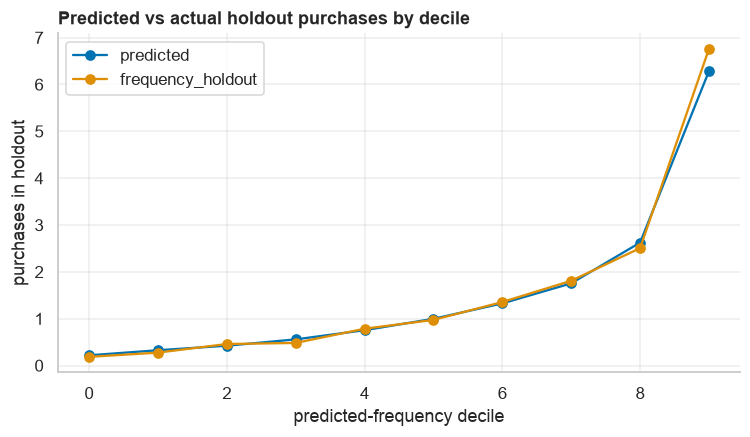

In [13]:
cal = load_processed("clv_cal_holdout").set_index("CustomerID")
bgf_cal = models.load_model("clv_calibration")["bgf_cal"]
cal["predicted"] = bgf_cal.conditional_expected_number_of_purchases_up_to_time(
    cal["duration_holdout"], cal["frequency_cal"], cal["recency_cal"], cal["T_cal"])
mae = (cal["predicted"] - cal["frequency_holdout"]).abs().mean()
print(f"holdout purchase-count MAE: {mae:.3f}")
by_decile = (cal.assign(decile=pd.qcut(cal["predicted"].rank(method="first"), 10,
                                        labels=False))
             .groupby("decile")[["predicted", "frequency_holdout"]].mean())
ax = by_decile.plot(figsize=(8, 4), marker="o",
                    color=[eda.PALETTE[0], eda.PALETTE[1]])
ax.set(title="Predicted vs actual holdout purchases by decile",
       xlabel="predicted-frequency decile", ylabel="purchases in holdout")
plt.show()
models.update_metrics("lens_E_validation", {"holdout_mae": float(mae)})

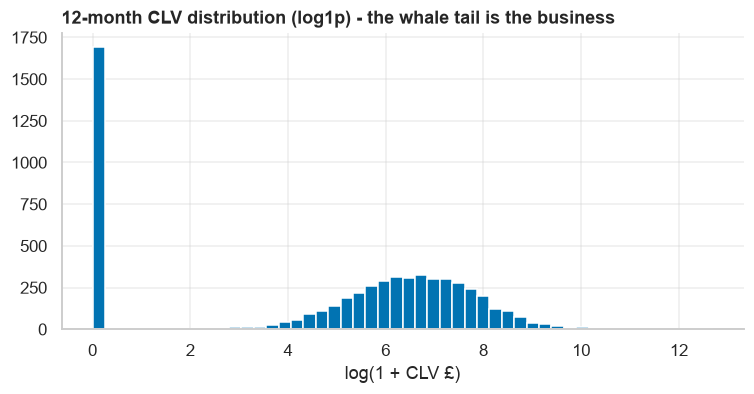

,CustomerID,frequency,monetary_value,clv
4061,16446,1.0,168469.600000,323584.772897
5692,18102,66.0,8768.193939,242653.699638
2277,14646,90.0,5809.905333,218978.145943
5050,17450,30.0,6851.561667,138069.181123
1731,14096,16.0,4071.434375,131944.077168


In [14]:
clv_summary = load_processed("clv_summary")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log1p(clv_summary["clv"]), bins=50, color=eda.PALETTE[0])
ax.set(title="12-month CLV distribution (log1p) - the whale tail is the business",
       xlabel="log(1 + CLV £)")
plt.show()
clv_summary.nlargest(5, "clv")[["CustomerID", "frequency", "monetary_value", "clv"]]

## 6. Synthesis - Revenue at Risk = P(churn) x CLV

Both per-customer numbers exist now (Telco: model probability x simplified CLV from
the survival bridge). Multiply, rank, and the suite's final product appears: **who to
call first, and what it is worth**.

In [15]:
from phase_1 import pipeline

scored, report = pipeline.score(telco.drop(columns=["Churn"]))
ranked, total = evaluation.revenue_at_risk(scored, "churn_probability", "clv_simple")
print(f"TOTAL revenue at risk (12-mo horizon, whole base): ${total:,.0f}")
top500 = ranked.head(500)
print(f"Top 500 customers hold ${top500['revenue_at_risk'].sum():,.0f} "
      f"({top500['revenue_at_risk'].sum()/total:.0%} of it)")
cols = ["customerID", "Contract", "tenure", "MonthlyCharges",
        "churn_probability", "risk_band", "expected_remaining_tenure",
        "clv_simple", "revenue_at_risk", "recommended_action"]
ranked[cols].head(15)

TOTAL revenue at risk (12-mo horizon, whole base): $3,606,272
Top 500 customers hold $1,130,368 (31% of it)


,customerID,Contract,tenure,MonthlyCharges,churn_probability,risk_band,expected_remaining_tenure,clv_simple,revenue_at_risk,recommended_action
1176,3992-YWPKO,Month-to-month,6,109.90,0.8446,Critical,50.0,5495.00,4641.077000,Offer 1-year contract discount
6963,9547-ITEFG,Month-to-month,9,102.60,0.8573,Critical,50.0,5130.00,4397.949000,Offer 1-year contract discount
2246,7181-BQYBV,Month-to-month,1,102.45,0.8751,Critical,48.3,4948.34,4330.292334,Offer 1-year contract discount
6634,1465-VINDH,Month-to-month,10,102.10,0.8655,Critical,48.6,4962.06,4294.662930,Offer 1-year contract discount
3085,5052-PNLOS,Month-to-month,3,105.35,0.8870,Critical,44.3,4667.00,4139.629000,Offer 1-year contract discount
5090,6502-HCJTI,Month-to-month,7,94.70,0.8485,Critical,51.3,4858.11,4122.106335,Offer 1-year contract discount
6894,1400-MMYXY,Month-to-month,3,105.90,0.8808,Critical,43.1,4564.29,4020.226632,Offer 1-year contract discount
2263,2506-CLAKW,Month-to-month,6,98.15,0.8401,Critical,48.6,4770.09,4007.352609,Offer 1-year contract discount
4459,3178-FESZO,Month-to-month,1,100.25,0.8926,Critical,44.2,4431.05,3955.155230,Offer 1-year contract discount
3141,5649-ANRML,Month-to-month,2,95.10,0.8417,Critical,48.9,4650.39,3914.233263,Offer 1-year contract discount


## 7. Model cards - honest one-paragraph summaries

Written to `models/metrics.json`; the app's Model Info tab reads them.

In [16]:
models.update_metrics("model_cards", {
    "lens_A": "HistGradientBoosting on 7,043 Telco customers (80/20 stratified). "
              "Test ROC-AUC ~0.84-0.86, PR-AUC ~0.65. Cost-optimal threshold ~0.3-0.35 "
              "under $500/$50 costs. Limitation: no usage/behavior features; "
              "long-tenure quiet quitters under-detected.",
    "lens_B": "Cox PH, C-index ~0.85. Expected-remaining-tenure is a ranking tool, "
              "not a per-customer guarantee; proportional-hazards assumption "
              "unchecked for some covariates.",
    "lens_C": "Best of 3 uplift meta-learners on MegaFon (600K, randomized). "
              "Judged on Qini AUC; features anonymized -> no interpretability. "
              "ClassTransformation result carries a propensity!=0.5 caveat.",
    "lens_D": "K-Means (k by silhouette) on scaled engineered features; clusters "
              "validated by churn-rate spread and human-readable profiles.",
    "lens_E": "BG/NBD + Gamma-Gamma, 180-day holdout validated (MAE printed above). "
              "One-time buyers priced 0; independence assumption checked.",
})
print("model cards written to models/metrics.json")

model cards written to models/metrics.json


**Next:** `05_pipeline_tool.ipynb` - wrap every artifact behind one `score()` call,
prove it on broken data, and expose CLI + app.